# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    root_mean_squared_error, mean_absolute_error, r2_score
)
from lightgbm import LGBMRegressor
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Anchor working directory to day-10-retail-demand-prediction/src
PROJECT_SRC = r"C:\Users\adjis\github\100-days-real-world-ml\day-10-retail-demand-prediction\src"
if os.path.exists(PROJECT_SRC):
    os.chdir(PROJECT_SRC)
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "../data/raw/Walmart.csv"
df_raw = pd.read_csv(CSV_PATH)
print(f"Working directory : {os.getcwd()}")
print(f"Raw Dataset Shape : {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory : C:\Users\adjis\github\100-days-real-world-ml\day-10-retail-demand-prediction\src
Raw Dataset Shape : 6,435 rows, 8 columns


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


# EDA 1: Schema, Date Format Verification & Store Panel Completeness

In [2]:
print(f"Total Missing Values : {df_raw.isnull().sum().sum()}")
print(f"Exact Duplicate Rows : {df_raw.duplicated().sum()}")
print(f"Unique Stores        : {df_raw['Store'].nunique()} (IDs {df_raw['Store'].min()} to {df_raw['Store'].max()})")

# Check if every store has the exact same number of weekly records (balanced panel check)
weeks_per_store = df_raw.groupby("Store")["Date"].nunique()
print(f"Weeks per Store      : Min={weeks_per_store.min()}, Max={weeks_per_store.max()}")

# Verify Date format (DD-MM-YYYY) before parsing
parsed_dates_preview = pd.to_datetime(df_raw["Date"], dayfirst=True)
print(f"Date Range (dayfirst=True): {parsed_dates_preview.min().date()} to {parsed_dates_preview.max().date()}")

audit_records = []
for col in df_raw.columns:
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Null_Count": df_raw[col].isnull().sum(),
        "Unique_Values": df_raw[col].nunique(),
        "Sample_Values": str(df_raw[col].unique()[:3]),
    })
display(pd.DataFrame(audit_records))

Total Missing Values : 0
Exact Duplicate Rows : 0
Unique Stores        : 45 (IDs 1 to 45)
Weeks per Store      : Min=143, Max=143
Date Range (dayfirst=True): 2010-02-05 to 2012-10-26


,Column,Dtype,Null_Count,Unique_Values,Sample_Values
0,Store,int64,0,45,[1 2 3]
1,Date,str,0,143,"<StringArray>\n['05-02-2010', '12-02-2010', '1..."
2,Weekly_Sales,float64,0,6435,[1643690.9 1641957.44 1611968.17]
3,Holiday_Flag,int64,0,2,[0 1]
4,Temperature,float64,0,3528,[42.31 38.51 39.93]
5,Fuel_Price,float64,0,892,[2.572 2.548 2.514]
6,CPI,float64,0,2145,[211.0963582 211.2421698 211.2891429]
7,Unemployment,float64,0,349,[8.106 7.808 7.787]


# EDA 2: Holiday Surge, Store Volume Disparity & Macroeconomic Correlations

Weekly Sales Summary (Holiday vs. Non-Holiday):


,count,mean,std,min,25%,50%,75%,max
Holiday_Flag,,,,,,,,
0,5985.0,1041256.38,558957.44,209986.25,551378.39,956211.20,1414343.53,3818686.45
1,450.0,1122887.89,627684.93,215359.21,575865.48,1018538.04,1555213.18,3004702.33


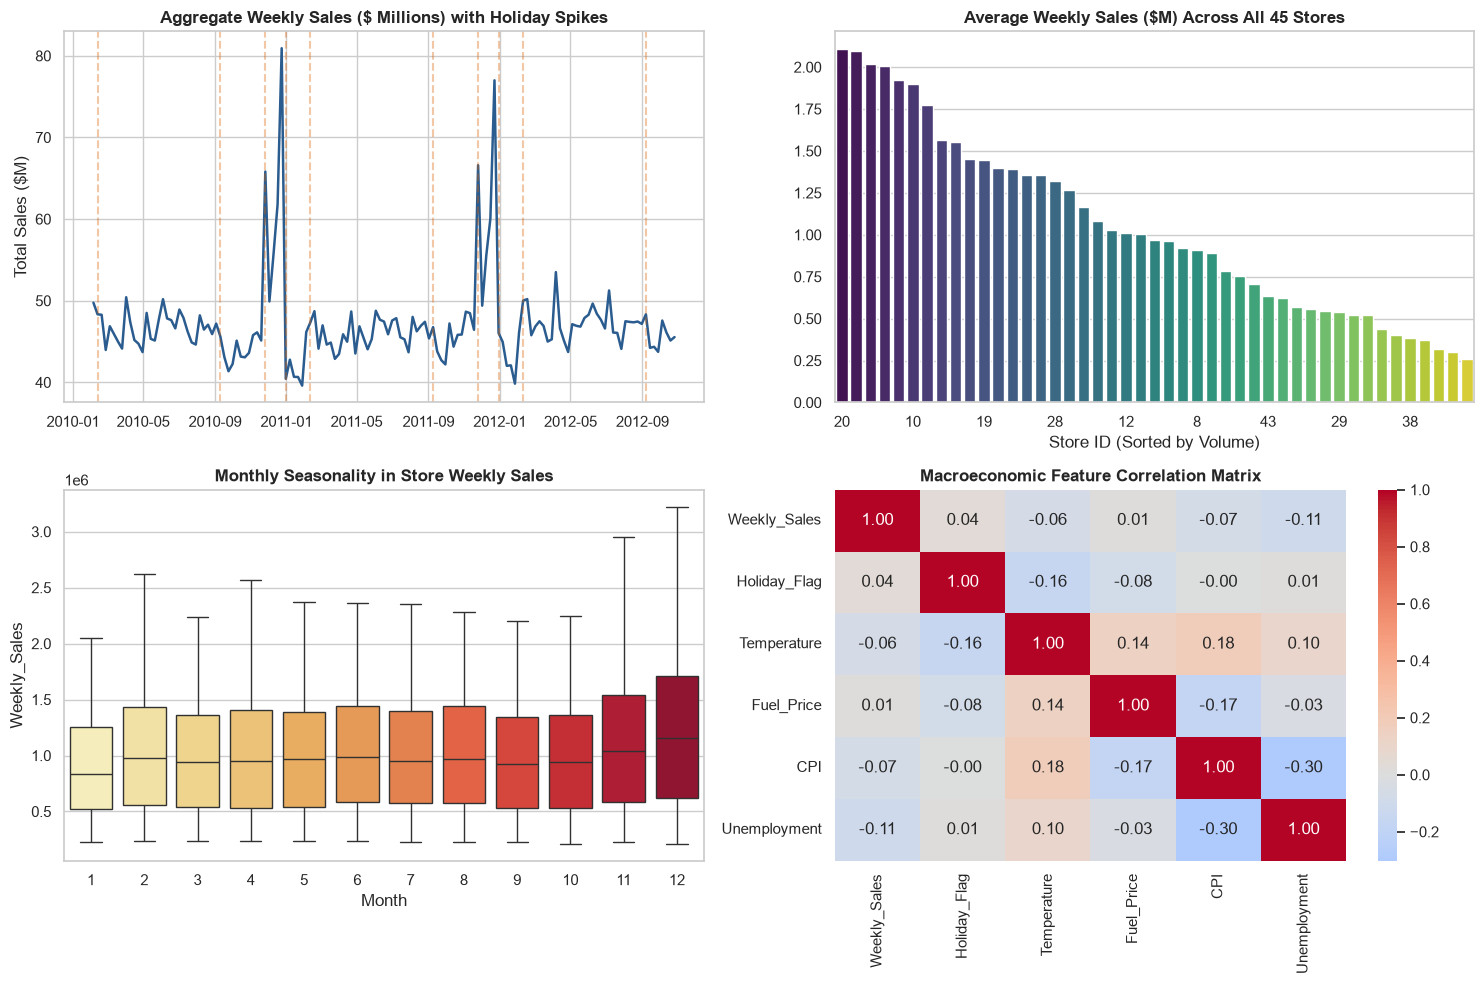

In [3]:
temp_df = df_raw.copy()
temp_df["Parsed_Date"] = pd.to_datetime(temp_df["Date"], dayfirst=True)
temp_df["Month"] = temp_df["Parsed_Date"].dt.month

print("Weekly Sales Summary (Holiday vs. Non-Holiday):")
display(temp_df.groupby("Holiday_Flag")["Weekly_Sales"].describe().round(2))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Total Weekly Sales Time Series Across All 45 Stores
weekly_total = temp_df.groupby("Parsed_Date")["Weekly_Sales"].sum() / 1e6
axes[0, 0].plot(weekly_total.index, weekly_total.values, color="#2b5c8f", linewidth=1.8)
holiday_dates = temp_df[temp_df["Holiday_Flag"] == 1]["Parsed_Date"].unique()
for hd in holiday_dates:
    axes[0, 0].axvline(hd, color="#d95f02", alpha=0.35, linestyle="--")
axes[0, 0].set_title("Aggregate Weekly Sales ($ Millions) with Holiday Spikes", fontweight="bold")
axes[0, 0].set_ylabel("Total Sales ($M)")

# Plot 2: Store-Level Sales Disparity (Top 10 vs Bottom 10 Stores)
store_avg = temp_df.groupby("Store")["Weekly_Sales"].mean().sort_values(ascending=False) / 1e6
sns.barplot(x=store_avg.index.astype(str), y=store_avg.values, palette="viridis", ax=axes[0, 1])
axes[0, 1].set_title("Average Weekly Sales ($M) Across All 45 Stores", fontweight="bold")
axes[0, 1].set_xlabel("Store ID (Sorted by Volume)")
axes[0, 1].set_xticks(range(0, 45, 5))

# Plot 3: Seasonality by Month (Showing Nov/Dec Holiday Surge)
sns.boxplot(data=temp_df, x="Month", y="Weekly_Sales", palette="YlOrRd", showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Monthly Seasonality in Store Weekly Sales", fontweight="bold")

# Plot 4: Macroeconomic & Environmental Correlation Heatmap
corr_cols = ["Weekly_Sales", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
sns.heatmap(temp_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 1])
axes[1, 1].set_title("Macroeconomic Feature Correlation Matrix", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/eda_retail_demand.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning & Chronological Sorting

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Parse 'Date' strictly using dayfirst=True (DD-MM-YYYY format verified in Cell 2).
2. Sort chronologically by ['Store', 'Date'] so time-lag and rolling-window features
   never pull values from the future or cross between different stores.
3. Cast 'Store' to categorical string so Ridge Regression treats each store ID as an
   independent fixed-effect rather than a continuous number (1..45).
"""
df_clean = df_raw.copy()
df_clean["Date"] = pd.to_datetime(df_clean["Date"], dayfirst=True)
df_clean = df_clean.sort_values(by=["Store", "Date"]).reset_index(drop=True)
df_clean["Store"] = df_clean["Store"].astype(str)

print(f"Cleaned & Chronologically Sorted Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")

Cleaned & Chronologically Sorted Shape: 6,435 rows, 8 columns


# Temporal Lag Feature Engineering & Strict Out-of-Time Split

In [5]:
df_feat = df_clean.copy()

# 1. Calendar & Holiday Seasonality Features
df_feat["year"] = df_feat["Date"].dt.year
df_feat["month"] = df_feat["Date"].dt.month
df_feat["week_of_year"] = df_feat["Date"].dt.isocalendar().week.astype(int)
df_feat["is_year_end_peak"] = df_feat["week_of_year"].isin([47, 51, 52]).astype(int)  # Thanksgiving & Christmas

# 2. Store-Specific Autoregressive Lag & Rolling Features (strictly past-looking via shift)
grouped = df_feat.groupby("Store")["Weekly_Sales"]
df_feat["sales_lag_1w"] = grouped.shift(1)
df_feat["sales_lag_2w"] = grouped.shift(2)
df_feat["sales_lag_4w"] = grouped.shift(4)
df_feat["sales_rolling_4w_mean"] = grouped.transform(lambda s: s.shift(1).rolling(4).mean())
df_feat["sales_rolling_4w_std"] = grouped.transform(lambda s: s.shift(1).rolling(4).std())

# Drop the first 4 warm-up weeks per store where lags are NaN
df_feat = df_feat.dropna().reset_index(drop=True)

# 3. Strict Chronological Out-of-Time Split (80% earliest weeks = Train, 20% latest weeks = Test)
unique_dates = np.sort(df_feat["Date"].unique())
cutoff_date = unique_dates[int(len(unique_dates) * 0.80)]

train_mask = df_feat["Date"] < cutoff_date
test_mask = df_feat["Date"] >= cutoff_date

feature_cols = [c for c in df_feat.columns if c not in ["Weekly_Sales", "Date"]]
X_train = df_feat.loc[train_mask, feature_cols].copy()
y_train = df_feat.loc[train_mask, "Weekly_Sales"].values
X_test = df_feat.loc[test_mask, feature_cols].copy()
y_test = df_feat.loc[test_mask, "Weekly_Sales"].values

print(f"Chronological Cutoff Date : {pd.Timestamp(cutoff_date).date()}")
print(f"Train Set (Past Weeks)    : {X_train.shape[0]:,} rows | Test Set (Future Weeks) : {X_test.shape[0]:,} rows")

cat_cols = ["Store"]
num_cols = [c for c in feature_cols if c not in cat_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

Chronological Cutoff Date : 2012-04-20
Train Set (Past Weeks)    : 4,995 rows | Test Set (Future Weeks) : 1,260 rows


# Model Benchmarking (Ridge Baseline vs. LightGBM Demand Engine)

In [6]:
def compute_wape(y_true, y_pred):
    """Weighted Absolute Percentage Error — standard retail supply-chain forecasting metric."""
    return float(np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))) * 100.0

models = {
    "Ridge Regression (Temporal Lag Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=10.0, random_state=42)),
    ]),
    "LightGBM Regressor (Retail Demand Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LGBMRegressor(
            n_estimators=400,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=7,
            subsample=0.8,
            colsample_bytree=0.8,
            n_jobs=-1,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_wape = None, float("inf")

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = np.maximum(pipeline.predict(X_test), 0.0)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    wape = compute_wape(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\n---> {name}")
    print(f"WAPE : {wape:.2f}% | MAE : ${mae:,.2f} | RMSE : ${rmse:,.2f} | R² Score : {r2:.4f}")

    if wape < best_wape:
        best_wape = wape
        best_model = pipeline

joblib.dump(best_model, "outputs/best_retail_demand_model.joblib")


---> Ridge Regression (Temporal Lag Baseline)
WAPE : 4.86% | MAE : $50,477.91 | RMSE : $69,653.39 | R² Score : 0.9829

---> LightGBM Regressor (Retail Demand Engine)
WAPE : 3.91% | MAE : $40,623.04 | RMSE : $58,074.60 | R² Score : 0.9881


['outputs/best_retail_demand_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

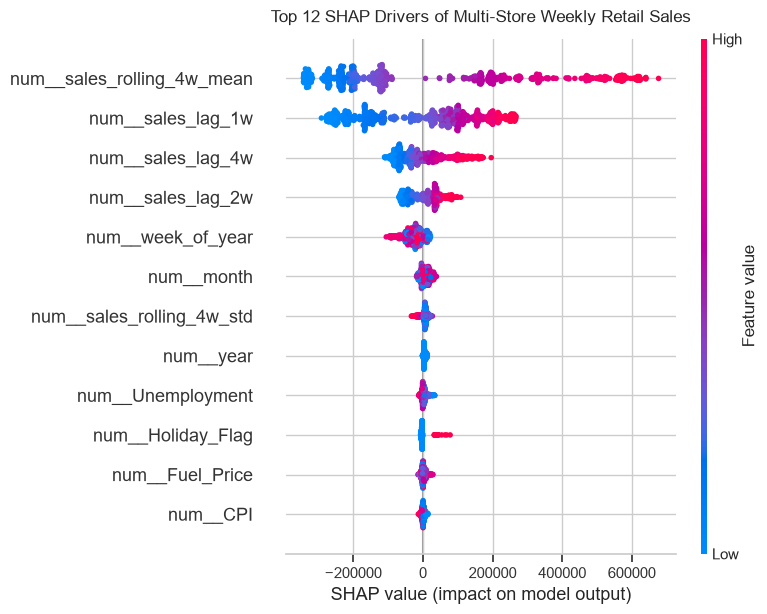

In [7]:
lgbm_pipe = models["LightGBM Regressor (Retail Demand Engine)"]

X_test_sample = X_test.sample(min(800, len(X_test)), random_state=42)
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["classifier"] if "classifier" in lgbm_pipe.named_steps else lgbm_pipe.named_steps["model"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Multi-Store Weekly Retail Sales", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_retail_demand.png", dpi=150)
plt.show()

# Holiday Week vs. Regular Week Forecast Accuracy Audit

In [8]:
lgbm_preds = np.maximum(models["LightGBM Regressor (Retail Demand Engine)"].predict(X_test), 0.0)

holiday_rows = []
for flag, label in [(0, "Regular Weeks (Holiday_Flag = 0)"), (1, "Holiday Weeks (Holiday_Flag = 1)")]:
    mask = (X_test["Holiday_Flag"] == flag).values
    holiday_rows.append({
        "Week_Type": label,
        "Store_Weeks": int(mask.sum()),
        "Mean_Actual_Sales ($)": y_test[mask].mean(),
        "MAE ($)": mean_absolute_error(y_test[mask], lgbm_preds[mask]),
        "WAPE (%)": compute_wape(y_test[mask], lgbm_preds[mask]),
    })
display(pd.DataFrame(holiday_rows).round(2))

,Week_Type,Store_Weeks,Mean_Actual_Sales ($),MAE ($),WAPE (%)
0,Regular Weeks (Holiday_Flag = 0),1215,1036381.50,39913.15,3.85
1,Holiday Weeks (Holiday_Flag = 1),45,1074001.32,59790.17,5.57
